# Identificación, estimación, simulación y pronóstico bajo el Movimiento Browniano Geométrico (MBG)

Este notebook es la traducción a Python del script MATLAB `IEPMBGPEII20262.m` (junto con las funciones `fractalvol.m` y `genhurst.m`). Sigue exactamente el mismo orden de pasos:

| Paso | Contenido |
|---|---|
| 0 | Descripción estadística del activo e histograma |
| 1 | PACF, dimensión fractal y exponente de Hurst |
| 2 | Retornos instantáneos y logarítmicos |
| 3 | Pruebas de normalidad de los retornos |
| 4 | Análisis de heterocedasticidad (ADF, ARCH, Ljung-Box) |
| 5 | Prueba gráfica de volatilidad constante |
| 6 | Estimación de parámetros ($\mu$, $\sigma$) |
| 7 | Pronósticos: a) inducido, b) simulado |

**Modelo:** $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, discretizado con Euler–Maruyama:
$S_{t+\Delta t} = S_t + \mu S_t \Delta t + \sigma S_t \sqrt{\Delta t}\,\varepsilon,\quad \varepsilon\sim N(0,1)$.

**Datos de entrada:** un archivo CSV con columnas `date,value` (por ejemplo, la serie diaria de la UVR). Cambie el nombre en la variable `archivo` de la celda de parámetros.

## Librerías y parámetros de configuración

In [126]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox, normal_ad, lilliefors

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 13, "axes.labelsize": 11})
pd.options.display.float_format = "{:,.6f}".format

# ======================= PARÁMETROS EDITABLES =======================
archivo = "UVR_daily_2015_2025.csv"   # Nombre del archivo CSV (columnas: date,value)
dt = 1/12                  # Frecuencia de los datos (365 días/año).
                            # Para una UVR diaria (todos los días calendario) a veces se usa dt = 1/365
semilla = 12345             # Semilla para reproducibilidad
k = 10000                    # Número de trayectorias a simular
n_plot = 150                # Trayectorias que se dibujan en los gráficos (solo afecta la figura, no los cálculos)
lags_pacf = 20              # Retardos para las PACF (parcorr de MATLAB usa 20 por defecto)
q_arch = 5                  # Retardos del test ARCH de Engle
q_lbq = 5                   # Retardos del test Ljung-Box
alpha = 0.05                # Nivel de significancia de las pruebas
# =====================================================================

## Funciones auxiliares

Traducción de `fractalvol.m` (dimensión fractal por conteo de cajas) y `genhurst.m` (exponente de Hurst generalizado, T. Aste 2013), más algunas utilidades (MAPE, cuantiles y estadísticos descriptivos).

In [127]:
def _percentil_matlab(x, p):
    """Percentiles con la misma convención de MATLAB (prctile/iqr/quantile): método 'hazen'."""
    try:
        return np.percentile(x, p, method="hazen")
    except TypeError:               # versiones antiguas de numpy
        return np.percentile(x, p)


def quantil_matlab(a, probs, axis=0):
    """Equivalente a quantile(a, probs) de MATLAB."""
    try:
        return np.quantile(a, probs, axis=axis, method="hazen")
    except TypeError:
        return np.quantile(a, probs, axis=axis)


def fractalvol(data):
    """
    [dimension, standard_dev] = fractalvol(data)

    Calcula la dimensión fractal de una caminata aleatoria 1D (data), asumida como función de sus
    índices. Se incrusta la serie en el cuadrado unitario (eje y = valores reescalados,
    eje x = índice/longitud) y se cuenta el número de cajas de lado 2^-j.
    Devuelve la dimensión y la desviación estándar de la pendiente (teoría MCO).
    """
    data = np.asarray(data, dtype=float)
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    if data.shape[0] < data.shape[1]:
        data = data.T
    if data.shape[1] == 1:
        data = np.column_stack([np.arange(1, len(data) + 1), data[:, 0]])
    data = data[np.argsort(data[:, 0], kind="stable")]

    max1, min1 = data[:, 0].max(), data[:, 0].min()
    max2, min2 = data[:, 1].max(), data[:, 1].min()

    # Normalizar todo al cuadrado unitario
    normdata = data.copy()
    normdata[:, 0] = (normdata[:, 0] - min1) / (max1 - min1)
    normdata[:, 1] = (normdata[:, 1] - min2) / (max2 - min2)
    xs, ys = normdata[:, 0], normdata[:, 1]

    # Asegurar que ningún punto "se cae" por el eje x
    minwidth = np.min(np.diff(xs))
    minwidth = np.log2(minwidth)
    minwidth = int(abs(np.ceil(minwidth))) - 1
    if minwidth < 3:
        raise ValueError("Serie demasiado corta para estimar la dimensión fractal.")

    n = np.zeros(minwidth)
    for j in range(1, minwidth + 1):
        width = 2.0 ** -j
        xaxis_pos = 0.0
        boxcount = 0
        while xaxis_pos < 1:
            # columna vertical: xaxis_pos <= x < xaxis_pos + width (xs está ordenado)
            lo = np.searchsorted(xs, xaxis_pos, side="left")
            hi = np.searchsorted(xs, xaxis_pos + width, side="left")
            if 1 - xaxis_pos == width:      # última columna: incluye el último punto (x = 1)
                hi = len(xs)
            vertical_column = ys[lo:hi]

            if len(vertical_column) == 1:
                boxcount += 1
            elif len(vertical_column) > 1:
                rawcount = (vertical_column.max() - vertical_column.min()) / width
                rawcount = rawcount + np.fmod(vertical_column.min(), width)   # rem() de MATLAB
                boxcount += int(np.ceil(rawcount))
            xaxis_pos += width              # avanzar sobre el eje x
        n[j - 1] = boxcount

    r = 2.0 ** -np.arange(1, minwidth + 1)
    s = -np.gradient(np.log(n)) / np.gradient(np.log(r))
    IQR = _percentil_matlab(s, 75) - _percentil_matlab(s, 25)
    indx2 = np.abs(s - np.median(s)) > IQR / 2     # descarta pendientes atípicas
    x2 = np.log(r)[~indx2]
    y2 = np.log(n)[~indx2]

    # La desviación estándar es la de la pendiente según la teoría MCO
    X = np.column_stack([np.ones_like(x2), x2])
    beta = np.linalg.pinv(X) @ y2
    C = np.linalg.pinv(X.T @ X)
    e = y2 - X @ beta
    sigma = np.sqrt((e @ e) * C)

    dimension = -beta[1]
    standard_dev = sigma[1, 1]
    return dimension, standard_dev


def genhurst(S, q=1, maxT=19):
    """
    mH, sH = genhurst(S, q=1, maxT=19)

    Exponente de Hurst generalizado H(q) a partir del escalamiento de los q-momentos renormalizados:
        <|x(t+r)-x(t)|^q> / <x(t)^q> ~ r^[q H(q)]
    S    : serie 1D (se recomienda T > 50)
    q    : exponente (escalar o vector). Por defecto q=1
    maxT : ventana máxima de escalamiento. Por defecto 19
    Devuelve H(q) y su desviación estándar sH(q) (escalares si q es escalar).
    Referencias: Di Matteo et al., Physica A 324 (2003); J. Banking & Finance 29 (2005); Quant. Finance 7 (2007).
    """
    S = np.asarray(S, dtype=float).ravel()
    q_escalar = np.isscalar(q)
    q = np.atleast_1d(np.asarray(q, dtype=float))
    L = len(S)
    lq = len(q)
    if L < max(maxT * 4, 60):
        warnings.warn("Data serie very short!")

    H = []
    for Tmax in range(5, maxT + 1):
        x = np.arange(1, Tmax + 1)
        mcord = np.zeros((Tmax, lq))
        for tt in range(1, Tmax + 1):
            # Índices 1-based de MATLAB convertidos a 0-based
            idx = np.arange(tt + 1, L + 1, tt)                  # (tt+1):tt:L
            dV = S[idx - 1] - S[idx - tt - 1]
            idx2 = np.arange(tt + 1, L + tt + 1, tt)            # (tt+1):tt:(L+tt)
            VV = S[idx2 - tt - 1]
            N = len(dV) + 1
            X = np.arange(1, N + 1)
            Y = VV
            mx = X.sum() / N
            SSxx = (X ** 2).sum() - N * mx ** 2
            my = Y.sum() / N
            SSxy = (X * Y).sum() - N * mx * my
            cc1 = SSxy / SSxx
            cc2 = my - cc1 * mx
            ddVd = dV - cc1
            VVVd = VV - cc1 * X - cc2
            for qq in range(lq):
                mcord[tt - 1, qq] = np.mean(np.abs(ddVd) ** q[qq]) / np.mean(np.abs(VVVd) ** q[qq])

        lx = np.log10(x)
        mx = lx.mean()
        SSxx = (lx ** 2).sum() - Tmax * mx ** 2
        fila = np.zeros(lq)
        for qq in range(lq):
            lm = np.log10(mcord[:, qq])
            my = lm.mean()
            SSxy = (lx * lm).sum() - Tmax * mx * my
            fila[qq] = SSxy / SSxx
        H.append(fila)

    H = np.array(H)
    mH = H.mean(axis=0) / q
    sH = H.std(axis=0, ddof=1) / q
    if q_escalar:
        return float(mH[0]), float(sH[0])
    return mH, sH


def mape(real, pron):
    """Error porcentual absoluto medio (MAPE, en %). 'pron' puede ser (N,) o (k, N): devuelve un valor por fila."""
    real = np.asarray(real, dtype=float)
    pron = np.asarray(pron, dtype=float)
    return np.mean(np.abs((real - pron) / real), axis=-1) * 100


def descripcion_estadistica(v):
    """[min max media mediana moda varianza desv.est. curtosis asimetría] como en EstadX de MATLAB."""
    v = np.asarray(v, dtype=float)
    vals, cuentas = np.unique(v, return_counts=True)
    moda = vals[np.argmax(cuentas)]          # en empates, el menor (igual que mode de MATLAB)
    return pd.Series({
        "Mínimo": v.min(),
        "Máximo": v.max(),
        "Media": v.mean(),
        "Mediana": np.median(v),
        "Moda": moda,
        "Varianza": v.var(ddof=1),
        "Desv. estándar": v.std(ddof=1),
        "Curtosis": stats.kurtosis(v, fisher=False),   # curtosis de Pearson (normal = 3), como MATLAB
        "Asimetría": stats.skew(v),
    })


def formato_fechas(ax):
    """Eje x con fechas legibles."""
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

## Carga de datos

Se lee el CSV (`date,value`), se convierte `date` a `datetime` y se separan:
- `dates`: fechas reales (solo para los ejes de los gráficos);
- `X`: array numérico con los valores (único insumo de los cálculos estocásticos y de retornos).

In [128]:
df = pd.read_csv(archivo)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").dropna(subset=["UVR"]).reset_index(drop=True)

dates = df["date"]                         # solo para graficar
X = df["UVR"].to_numpy(dtype=float)        # serie del activo subyacente
N = len(X)

if np.any(X <= 0):
    raise ValueError("El MBG requiere valores estrictamente positivos (se usan cocientes y logaritmos).")

print(f"Archivo: {archivo}")
print(f"Observaciones: {N}  |  Desde {dates.iloc[0].date()} hasta {dates.iloc[-1].date()}")
print(f"dt = {dt:.6f}  (≈ 1/{1/dt:.0f})")
df.head()

Archivo: UVR_daily_2015_2025.csv
Observaciones: 4018  |  Desde 2015-01-01 hasta 2025-12-31
dt = 0.083333  (≈ 1/12)


,date,UVR
0,2015-01-01,215.042400
1,2015-01-02,215.051400
2,2015-01-03,215.060400
3,2015-01-04,215.069400
4,2015-01-05,215.078400


## Análisis cuantitativo de la serie

### Gráfica del activo

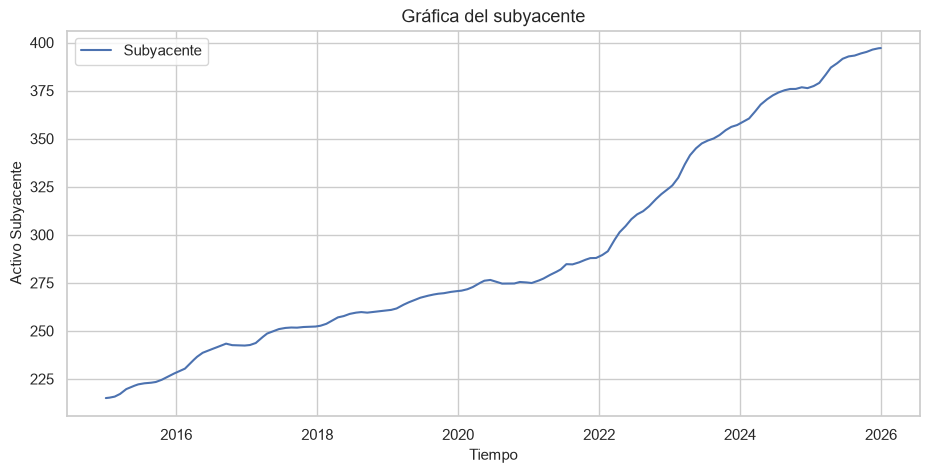

In [129]:
fig, ax = plt.subplots()
ax.plot(dates, X, label="Subyacente")
ax.set_xlabel("Tiempo")
ax.set_ylabel("Activo Subyacente")
ax.set_title("Gráfica del subyacente")
ax.legend()
formato_fechas(ax)
plt.show()

### Paso 0: Descripción estadística del activo

,Mínimo,Máximo,Media,Mediana,Moda,Varianza,Desv. estándar,Curtosis,Asimetría
Subyacente,215.042400,397.122700,291.240949,274.759600,274.590000,"2,820.622175",53.109530,2.109320,0.624286


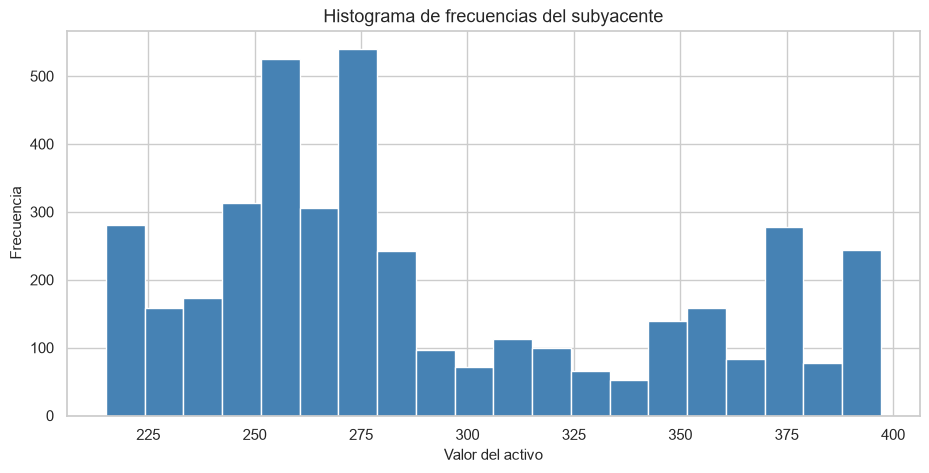

In [130]:
EstadX = descripcion_estadistica(X).to_frame("Subyacente").T
display(EstadX)

fig, ax = plt.subplots()
ax.hist(X, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Valor del activo")
ax.set_ylabel("Frecuencia")
ax.set_title("Histograma de frecuencias del subyacente")
plt.show()

### Paso 1: Autocorrelación parcial, dimensión fractal y exponente de Hurst

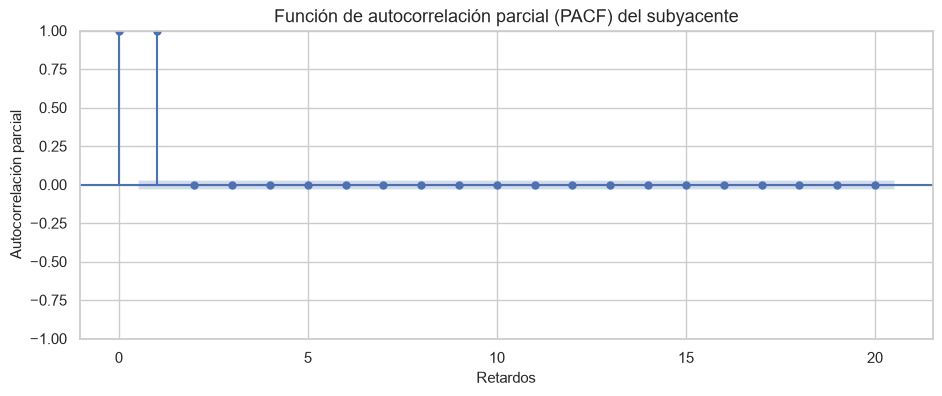

,Valor,Desv. estándar
Dimensión fractal (DF),1.013648,0.007582
Exponente de Hurst (EH),0.995340,0.001775
DF + EH,2.008989,NaN


Referencia: para un movimiento browniano estándar se espera DF + EH ≈ 2 (DF ≈ 1.5, EH ≈ 0.5).


In [131]:
fig, ax = plt.subplots(figsize=(11, 4))
plot_pacf(X, lags=lags_pacf, method="ywm", ax=ax)
ax.set_title("Función de autocorrelación parcial (PACF) del subyacente")
ax.set_xlabel("Retardos")
ax.set_ylabel("Autocorrelación parcial")
plt.show()

DF, DF_sd = fractalvol(X)      # Dimensión fractal
EH, EH_sd = genhurst(X)        # Exponente de Hurst (q = 1)
S_fh = DF + EH

Z_fh = pd.DataFrame(
    {"Valor": [DF, EH, S_fh], "Desv. estándar": [DF_sd, EH_sd, np.nan]},
    index=["Dimensión fractal (DF)", "Exponente de Hurst (EH)", "DF + EH"],
)
display(Z_fh)
print("Referencia: para un movimiento browniano estándar se espera DF + EH ≈ 2 (DF ≈ 1.5, EH ≈ 0.5).")

## Análisis cuantitativo de los retornos instantáneos

### Paso 2: Análisis de los retornos instantáneos

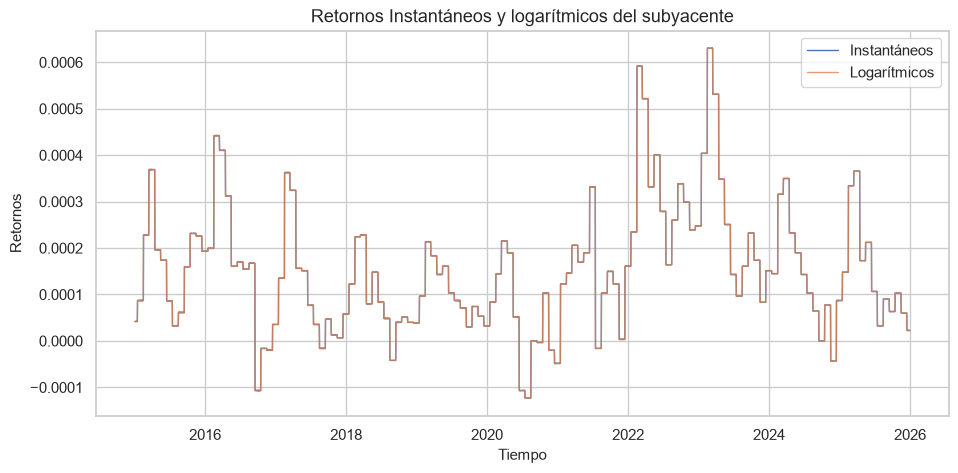

,Mínimo,Máximo,Media,Mediana,Moda,Varianza,Desv. estándar,Curtosis,Asimetría
Retornos,-0.000123,0.000631,0.000153,0.000145,0.000000,0.000000,0.000136,4.135889,0.885076


In [132]:
R = np.diff(X) / X[:-1]            # Retornos instantáneos (simples)
rl = np.log(X[1:] / X[:-1])        # Retornos logarítmicos
dates_r = dates.iloc[1:]           # fechas asociadas a los retornos

fig, ax = plt.subplots()
ax.plot(dates_r, R, label="Instantáneos", lw=1)
ax.plot(dates_r, rl, label="Logarítmicos", lw=1, alpha=0.8)
ax.set_xlabel("Tiempo")
ax.set_ylabel("Retornos")
ax.set_title("Retornos Instantáneos y logarítmicos del subyacente")
ax.legend()
formato_fechas(ax)
plt.show()

# Descripción estadística de los retornos
EstadR = descripcion_estadistica(R).to_frame("Retornos").T
display(EstadR)

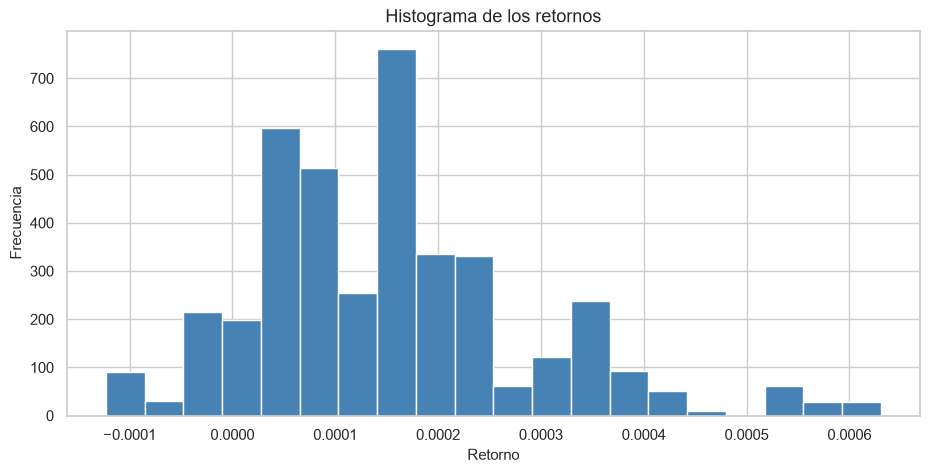

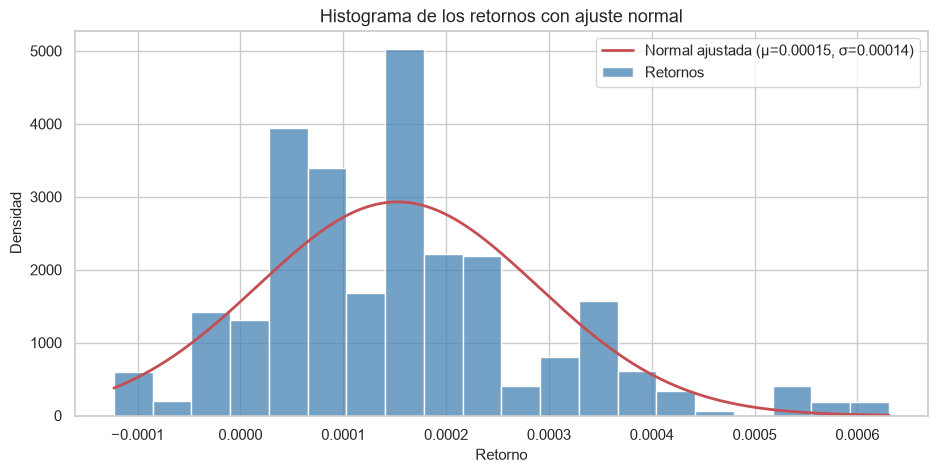

In [133]:
# Histograma de frecuencias de los retornos
fig, ax = plt.subplots()
ax.hist(R, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Retorno")
ax.set_ylabel("Frecuencia")
ax.set_title("Histograma de los retornos")
plt.show()

# Histograma con ajuste normal (equivalente a histfit)
mu_fit, sd_fit = stats.norm.fit(R)
xx = np.linspace(R.min(), R.max(), 400)
fig, ax = plt.subplots()
sns.histplot(R, bins=20, stat="density", color="steelblue", edgecolor="white", ax=ax, label="Retornos")
ax.plot(xx, stats.norm.pdf(xx, mu_fit, sd_fit), "r", lw=2, label=f"Normal ajustada (μ={mu_fit:.5f}, σ={sd_fit:.5f})")
ax.set_xlabel("Retorno")
ax.set_ylabel("Densidad")
ax.set_title("Histograma de los retornos con ajuste normal")
ax.legend()
plt.show()

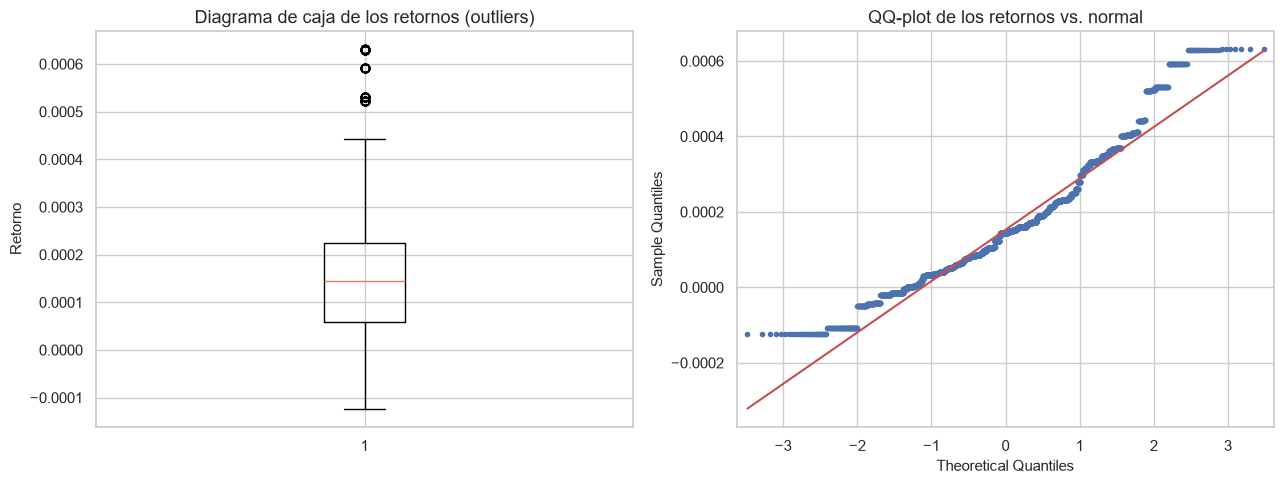

Observaciones atípicas (criterio 1.5·IQR del boxplot): 118 de 4017


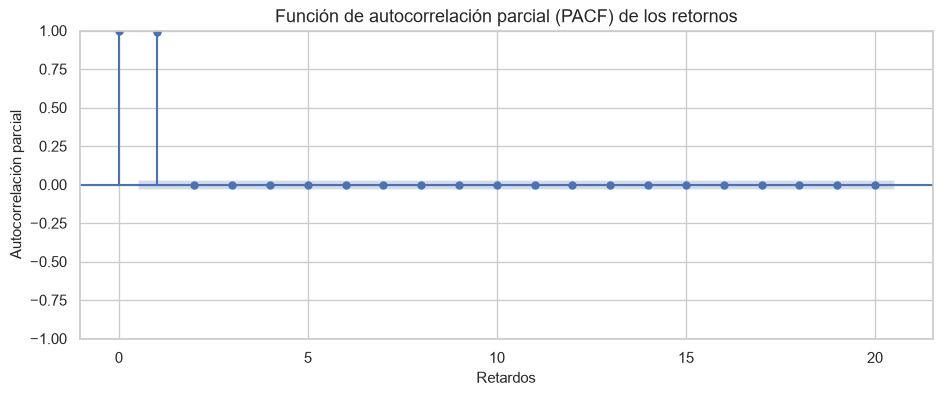

In [134]:
# Outliers: boxplot y QQ-plot
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
axs[0].boxplot(R, showfliers=True)
axs[0].set_title("Diagrama de caja de los retornos (outliers)")
axs[0].set_ylabel("Retorno")
sm.qqplot(R, line="s", ax=axs[1], markersize=3)
axs[1].set_title("QQ-plot de los retornos vs. normal")
plt.tight_layout()
plt.show()

q1, q3 = _percentil_matlab(R, 25), _percentil_matlab(R, 75)
iqr_R = q3 - q1
n_out = int(np.sum((R < q1 - 1.5 * iqr_R) | (R > q3 + 1.5 * iqr_R)))
print(f"Observaciones atípicas (criterio 1.5·IQR del boxplot): {n_out} de {len(R)}")
# Para remover un outlier (equivalente a R(####)=[] en MATLAB):  R = np.delete(R, indice)

fig, ax = plt.subplots(figsize=(11, 4))
plot_pacf(R, lags=lags_pacf, method="ywm", ax=ax)
ax.set_title("Función de autocorrelación parcial (PACF) de los retornos")
ax.set_xlabel("Retardos")
ax.set_ylabel("Autocorrelación parcial")
plt.show()

### Paso 3: Pruebas de normalidad para los retornos

Equivalencias: `jbtest` → Jarque-Bera; `kstest` → Kolmogorov-Smirnov sobre retornos estandarizados; `adtest` → Anderson-Darling; `lillietest` → Lilliefors. `h = 1` indica rechazo de la normalidad al nivel `alpha`.

In [135]:
m = R.mean()                       # Media muestral de los retornos
des = R.std(ddof=1)                # Desviación estándar de los retornos
Zn = (R - m) / des                 # Retornos normalizados para el QQ-plot y la prueba KS

jb_stat, jb_p = stats.jarque_bera(R)
ks_stat, ks_p = stats.kstest(Zn, "norm")
ad_stat, ad_p = normal_ad(R)
lil_stat, lil_p = lilliefors(R, dist="norm")

PNorRet = pd.DataFrame({
    "Estadístico": [jb_stat, ks_stat, ad_stat, lil_stat],
    "Valor-p": [jb_p, ks_p, ad_p, lil_p],
}, index=["Jarque-Bera (jbtest)", "Kolmogorov-Smirnov (kstest)", "Anderson-Darling (adtest)", "Lilliefors (lillietest)"])
PNorRet["h (1 = rechaza normalidad)"] = (PNorRet["Valor-p"] < alpha).astype(int)
display(PNorRet)

if PNorRet["h (1 = rechaza normalidad)"].sum() == 0:
    print("Ninguna prueba rechaza la normalidad de los retornos.")
else:
    print(f"Se rechaza la normalidad en {PNorRet['h (1 = rechaza normalidad)'].sum()} de 4 pruebas (nivel {alpha:.0%}).")

,Estadístico,Valor-p,h (1 = rechaza normalidad)
Jarque-Bera (jbtest),740.414250,0.000000,1
Kolmogorov-Smirnov (kstest),0.099620,0.000000,1
Anderson-Darling (adtest),50.779616,0.000000,1
Lilliefors (lillietest),0.099620,0.001000,1


Se rechaza la normalidad en 4 de 4 pruebas (nivel 5%).


### Paso 4: Análisis de heterocedasticidad

Perturbaciones aleatorias estandarizadas $E_t = (R_t - \bar R)/\sqrt{\Delta t}$ y su cuadrado $E_t^2$.

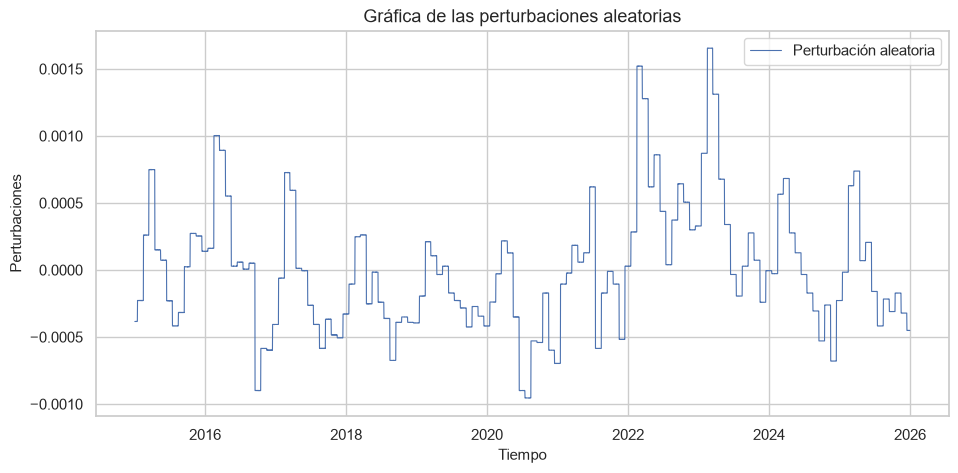

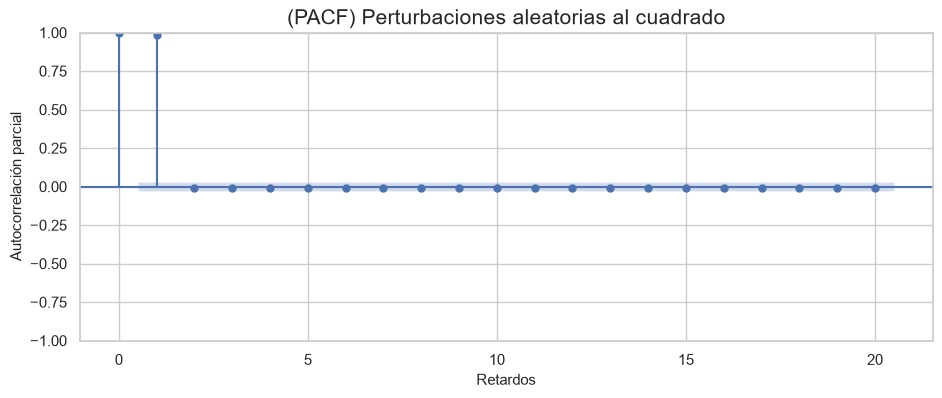

In [136]:
Et = (R - R.mean()) / np.sqrt(dt)
Et2 = Et ** 2

fig, ax = plt.subplots()
ax.plot(dates_r, Et, label="Perturbación aleatoria", lw=0.8)
ax.set_xlabel("Tiempo")
ax.set_ylabel("Perturbaciones")
ax.set_title("Gráfica de las perturbaciones aleatorias")
ax.legend()
formato_fechas(ax)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
plot_pacf(Et2, lags=lags_pacf, method="ywm", ax=ax, label="PACF")
ax.set_title("(PACF) Perturbaciones aleatorias al cuadrado", fontsize=15)
ax.set_xlabel("Retardos")
ax.set_ylabel("Autocorrelación parcial")
plt.show()

In [137]:
# ---- Test ADF sobre las perturbaciones (adftest de MATLAB: modelo AR sin constante, 0 rezagos)
res_adf = adfuller(Et, maxlag=0, regression="n", autolag=None)
adf_stat, adf_p, adf_crit = res_adf[0], res_adf[1], res_adf[4]
h_adf = int(adf_p < alpha)

TADF = pd.DataFrame({"h": [h_adf], "Valor Crítico (5%)": [adf_crit["5%"]],
                     "Estadístico": [adf_stat], "Valor-p": [adf_p]}, index=["ADF"])
display(TADF)
print("\n--- Test ADF sobre las perturbaciones aleatorias ---")
print(f"Estadístico ADF: {adf_stat:.4f}")
print(f"Valor crítico al 5%: {adf_crit['5%']:.4f}")
print(f"Valor-p: {adf_p:.4f}")
if h_adf == 1:
    print("Resultado: Se rechaza H0. Las perturbaciones son estacionarias (no hay raíz unitaria).")
else:
    print("Resultado: No se rechaza H0. Las perturbaciones NO son estacionarias.")

# Referencia adicional (variante con constante y selección automática de rezagos por AIC)
adf_c = adfuller(Et, regression="c", autolag="AIC")
print(f"\n[Referencia] ADF con constante y rezagos AIC: estadístico = {adf_c[0]:.4f}, valor-p = {adf_c[1]:.4f}, rezagos = {adf_c[2]}")

,h,Valor Crítico (5%),Estadístico,Valor-p
ADF,1,-1.941067,-4.339636,0.000019



--- Test ADF sobre las perturbaciones aleatorias ---
Estadístico ADF: -4.3396
Valor crítico al 5%: -1.9411
Valor-p: 0.0000
Resultado: Se rechaza H0. Las perturbaciones son estacionarias (no hay raíz unitaria).

[Referencia] ADF con constante y rezagos AIC: estadístico = -4.3391, valor-p = 0.0004, rezagos = 0


In [138]:
# ---- Test ARCH de Engle
print("--- Test ARCH (Engle) ---")
try:
    lm_arch, p_arch, f_arch, pf_arch = het_arch(Et, nlags=q_arch)
except TypeError:                      # versiones antiguas de statsmodels
    lm_arch, p_arch, f_arch, pf_arch = het_arch(Et, maxlag=q_arch)
crit_arch = stats.chi2.ppf(1 - alpha, q_arch)
h_arch = int(p_arch < alpha)

print(f"Estadístico ARCH: {lm_arch:.4f}")
print(f"Valor crítico al 5%: {crit_arch:.4f}")
print(f"Valor-p: {p_arch:.4f}")
TE = pd.DataFrame({"h": [h_arch], "Valor Crítico": [crit_arch],
                   "Estadístico": [lm_arch], "Valor-p": [p_arch]}, index=[f"ARCH ({q_arch} rezagos)"])
display(TE)
if h_arch == 1:
    print("Resultado: Se rechaza H0 - hay evidencia de heterocedasticidad condicional (efecto ARCH).")
else:
    print("Resultado: No se rechaza H0 - no se detecta heterocedasticidad condicional (no hay efecto ARCH).")

# ---- Test de Ljung-Box sobre Et^2
print("\n--- Test Ljung-Box sobre residuos^2 ---")
lb = acorr_ljungbox(Et2, lags=[q_lbq], return_df=True)
stat_lbq = float(lb["lb_stat"].iloc[0])
p_lbq = float(lb["lb_pvalue"].iloc[0])
crit_lbq = stats.chi2.ppf(1 - alpha, q_lbq)
h_lbq = int(p_lbq < alpha)

print(f"Estadístico Ljung-Box: {stat_lbq:.4f}")
print(f"Valor crítico al 5%: {crit_lbq:.4f}")
print(f"Valor-p: {p_lbq:.4f}")
TLB = pd.DataFrame({"h": [h_lbq], "Valor Crítico": [crit_lbq],
                    "Estadístico": [stat_lbq], "Valor-p": [p_lbq]}, index=[f"Ljung-Box ({q_lbq} rezagos)"])
display(TLB)
if h_lbq == 1:
    print("Resultado: Se rechaza H0 - hay autocorrelación en la varianza, posible efecto GARCH.")
else:
    print("Resultado: No se rechaza H0 - no se detecta autocorrelación en la varianza.")

--- Test ARCH (Engle) ---
Estadístico ARCH: 3876.1208
Valor crítico al 5%: 11.0705
Valor-p: 0.0000


,h,Valor Crítico,Estadístico,Valor-p
ARCH (5 rezagos),1,11.070498,"3,876.120812",0.000000


Resultado: Se rechaza H0 - hay evidencia de heterocedasticidad condicional (efecto ARCH).

--- Test Ljung-Box sobre residuos^2 ---
Estadístico Ljung-Box: 18111.4240
Valor crítico al 5%: 11.0705
Valor-p: 0.0000


,h,Valor Crítico,Estadístico,Valor-p
Ljung-Box (5 rezagos),1,11.070498,"18,111.423987",0.000000


Resultado: Se rechaza H0 - hay autocorrelación en la varianza, posible efecto GARCH.


### Paso 5: Prueba gráfica empírica de volatilidad constante

Volatilidad dinámica: desviación estándar de los retornos desde el primer dato hasta el dato $j$ (anualizada). Si el MBG es adecuado, la curva debe estabilizarse.

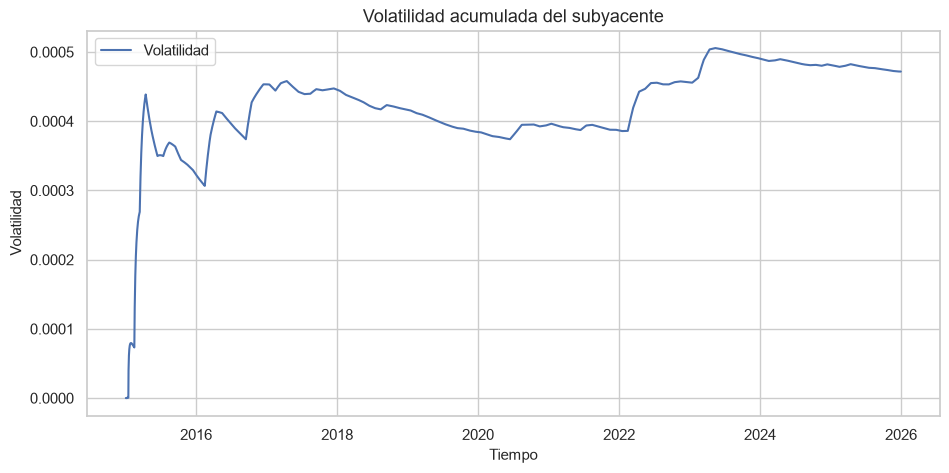

Volatilidad acumulada final (valor inicial de σ): 0.000472


In [139]:
VE = (pd.Series(R / np.sqrt(dt)).expanding().std(ddof=1).fillna(0.0)).to_numpy()   # volatilidad acumulada

fig, ax = plt.subplots()
ax.plot(dates_r, VE, label="Volatilidad")
ax.set_xlabel("Tiempo")
ax.set_ylabel("Volatilidad")
ax.set_title("Volatilidad acumulada del subyacente")
ax.legend()
formato_fechas(ax)
plt.show()

vol = VE[-1]     # Valor estimado inicial de la volatilidad constante
print(f"Volatilidad acumulada final (valor inicial de σ): {vol:.6f}")

### Paso 6: Estimación de parámetros

In [140]:
muest = R.mean() / dt                      # μ anualizado
sigmaest = np.sqrt(R.var(ddof=1) / dt)     # σ anualizado

Est = pd.DataFrame({"Estimación": [muest, sigmaest]}, index=["μ (deriva anualizada)", "σ (volatilidad anualizada)"])
display(Est)

,Estimación
μ (deriva anualizada),0.001833
σ (volatilidad anualizada),0.000472


### Paso 7: Pronósticos

Se usa un generador `np.random.default_rng(semilla)` para que los resultados sean reproducibles. Las trayectorias se calculan con $k$ réplicas; solo se dibujan `n_plot` de ellas.

In [141]:
rng = np.random.default_rng(semilla)

def graficar_pronostico(sim, banda, esperado, titulo, etiqueta_tray):
    """Trayectorias (gris), bandas de confianza 95% (rojo), datos reales (azul) y valor esperado (negro)."""
    fig, ax = plt.subplots(figsize=(12, 6))
    h1 = ax.plot(dates, sim[:n_plot].T, color="0.8", lw=0.6, zorder=1)
    h2 = ax.plot(dates, banda.T, "r--", lw=2, zorder=3)
    h3 = ax.plot(dates, X, "b", lw=1.5, zorder=4)
    h4 = ax.plot(dates, esperado, "k", lw=1.5, zorder=5)
    ax.set_title(titulo)
    ax.set_ylabel("Precios activo subyacente")
    ax.set_xlabel("Tiempo")
    ax.legend([h1[0], h2[0], h3[0], h4[0]],
              [etiqueta_tray, "Bandas de confianza 95%", "Datos reales", "Valor esperado"])
    formato_fechas(ax)
    plt.show()

def metricas_pronostico(sim, banda, esperado):
    """Cobertura de las bandas y MAPE (trayectorias y valor esperado)."""
    dentro = (banda[0] <= X) & (X <= banda[1])
    cobertura = dentro.mean()
    mape_tray = mape(X, sim)               # un MAPE por trayectoria
    rma = np.array([mape_tray.min(), mape_tray.mean(), mape_tray.max()])
    mape_esp = float(mape(X, esperado))
    return cobertura, rma, mape_esp

#### a) Pronóstico inducido

Cada paso parte del **valor real anterior** $X_{j-1}$ y le agrega la deriva y un ruido gaussiano:
$XI_{ij} = X_{j-1} + \hat\mu X_{j-1}\Delta t + \hat\sigma X_{j-1}\sqrt{\Delta t}\,\varepsilon_{ij}$.

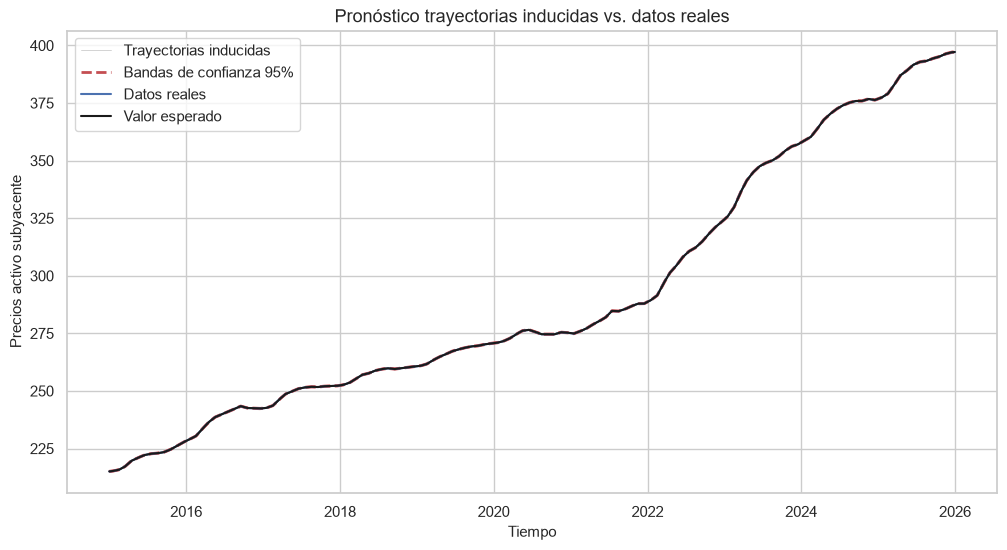

Proporción de datos reales dentro de las bandas (cobertura): 0.9552


,MAPE mín (%),MAPE medio (%),MAPE máx (%)
Trayectorias inducidas,0.014645,0.015187,0.015776


MAPE del valor esperado: 0.010319 %


In [142]:
XI = np.empty((k, N))
XI[:, 0] = X[0]
Zi = rng.standard_normal((k, N - 1))
XI[:, 1:] = X[:-1] * (1 + muest * dt) + sigmaest * X[:-1] * np.sqrt(dt) * Zi
del Zi

VECXI = XI.mean(axis=0)                           # valor esperado
CXICI = quantil_matlab(XI, [0.025, 0.975], axis=0)  # bandas de confianza 95% (2, N)

graficar_pronostico(XI, CXICI, VECXI, "Pronóstico trayectorias inducidas vs. datos reales", "Trayectorias inducidas")

PBBXI, rmaXI, mape_VECXI = metricas_pronostico(XI, CXICI, VECXI)
print(f"Proporción de datos reales dentro de las bandas (cobertura): {PBBXI:.4f}")
display(pd.DataFrame([rmaXI], columns=["MAPE mín (%)", "MAPE medio (%)", "MAPE máx (%)"], index=["Trayectorias inducidas"]))
print(f"MAPE del valor esperado: {mape_VECXI:.6f} %")

#### b) Pronóstico simulado

Trayectorias independientes a partir de $X_0$, donde cada paso usa el valor **simulado** anterior:
$XS_{ij} = XS_{i,j-1} + \hat\mu XS_{i,j-1}\Delta t + \hat\sigma XS_{i,j-1}\sqrt{\Delta t}\,\varepsilon_{ij}$.

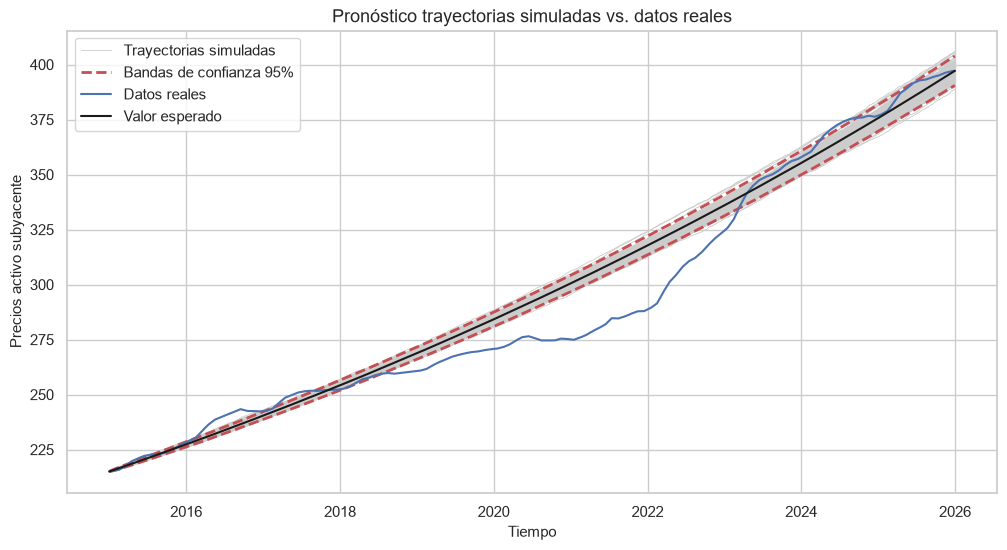

Proporción de datos reales dentro de las bandas (cobertura): 0.3547


,MAPE mín (%),MAPE medio (%),MAPE máx (%)
Trayectorias simuladas,2.638525,3.129560,4.302587


MAPE del valor esperado: 3.084567 %


In [143]:
XS = np.empty((k, N))
XS[:, 0] = X[0]
raiz_dt = np.sqrt(dt)
for j in range(1, N):
    XS[:, j] = XS[:, j - 1] * (1 + muest * dt + sigmaest * raiz_dt * rng.standard_normal(k))

VECXS = XS.mean(axis=0)
CXSCI = quantil_matlab(XS, [0.025, 0.975], axis=0)

graficar_pronostico(XS, CXSCI, VECXS, "Pronóstico trayectorias simuladas vs. datos reales", "Trayectorias simuladas")

PBBXS, rmaXS, mape_VECXS = metricas_pronostico(XS, CXSCI, VECXS)
print(f"Proporción de datos reales dentro de las bandas (cobertura): {PBBXS:.4f}")
display(pd.DataFrame([rmaXS], columns=["MAPE mín (%)", "MAPE medio (%)", "MAPE máx (%)"], index=["Trayectorias simuladas"]))
print(f"MAPE del valor esperado: {mape_VECXS:.6f} %")

## Resumen de resultados

In [144]:
resumen = pd.DataFrame({
    "Valor": [
        muest, sigmaest, vol, DF, EH, DF + EH,
        jb_p, adf_p, p_arch, p_lbq,
        PBBXI, rmaXI[1], mape_VECXI,
        PBBXS, rmaXS[1], mape_VECXS,
    ]
}, index=pd.MultiIndex.from_tuples([
    ("Parámetros", "μ anualizado"),
    ("Parámetros", "σ anualizado"),
    ("Parámetros", "σ acumulada final"),
    ("Fractal / memoria", "Dimensión fractal"),
    ("Fractal / memoria", "Exponente de Hurst"),
    ("Fractal / memoria", "DF + EH (≈ 2 en MBG)"),
    ("Diagnóstico (valor-p)", "Normalidad (Jarque-Bera)"),
    ("Diagnóstico (valor-p)", "ADF perturbaciones"),
    ("Diagnóstico (valor-p)", f"ARCH ({q_arch} rezagos)"),
    ("Diagnóstico (valor-p)", f"Ljung-Box Et² ({q_lbq} rezagos)"),
    ("Pronóstico inducido", "Cobertura bandas 95%"),
    ("Pronóstico inducido", "MAPE medio trayectorias (%)"),
    ("Pronóstico inducido", "MAPE valor esperado (%)"),
    ("Pronóstico simulado", "Cobertura bandas 95%"),
    ("Pronóstico simulado", "MAPE medio trayectorias (%)"),
    ("Pronóstico simulado", "MAPE valor esperado (%)"),
]))
resumen.loc[("Diagnóstico (valor-p)", "ADF perturbaciones"), "Valor"] = adf_p
display(resumen)

print(f"\nModelo estimado:  dS = {muest:.6f}·S·dt + {sigmaest:.6f}·S·dW   (dt = {dt:.6f}, N = {N}, k = {k})")
if p_arch < alpha or p_lbq < alpha or jb_p < alpha:
    print("Atención: hay evidencia de no normalidad y/o heterocedasticidad; el supuesto de MBG (σ constante, retornos normales) podría no ser adecuado.")
else:
    print("Las pruebas no contradicen los supuestos del MBG (retornos normales, σ constante).")

Valor
Parámetros            μ anualizado                0.001833
                      σ anualizado                0.000472
                      σ acumulada final           0.000472
Fractal / memoria     Dimensión fractal           1.013648
                      Exponente de Hurst          0.995340
                      DF + EH (≈ 2 en MBG)        2.008989
Diagnóstico (valor-p) Normalidad (Jarque-Bera)    0.000000
                      ADF perturbaciones          0.000019
                      ARCH (5 rezagos)            0.000000
                      Ljung-Box Et² (5 rezagos)   0.000000
Pronóstico inducido   Cobertura bandas 95%        0.955202
                      MAPE medio trayectorias (%) 0.015187
                      MAPE valor esperado (%)     0.010319
Pronóstico simulado   Cobertura bandas 95%        0.354654
                      MAPE medio trayectorias (%) 3.129560
                      MAPE valor esperado (%)     3.084567


Modelo estimado:  dS = 0.001833·S·dt + 0.000472·S·dW   (dt = 0.083333, N = 4018, k = 10000)
Atención: hay evidencia de no normalidad y/o heterocedasticidad; el supuesto de MBG (σ constante, retornos normales) podría no ser adecuado.
